In [ ]:
`
# STEP 1: LOAD THE AUSTRALIAN CREDIT APPROVAL DATASET

!pip -q install ucimlrepo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from ucimlrepo import fetch_ucirepo

# Download the official UCI dataset
dataset = fetch_ucirepo(id=143)

# Preserve the original feature values for correct preprocessing
X_raw = dataset.data.features.copy()
y_raw = dataset.data.targets.iloc[:, 0].copy()

# Basic inspection
print("Dataset loaded successfully!")
print("Feature matrix shape:", X_raw.shape)
print("Target shape:", y_raw.shape)
print("\nFirst five rows:")
display(X_raw.head())

print("\nFeature data types to:")
print(X_raw.dtypes)

print("\nTarget class distribution:")
print(y_raw.value_counts(dropna=False))

print("\nMissing values in features:", X_raw.isna().sum().sum())
print("Missing values in target:", y_raw.isna().sum())

Dataset loaded successfully!
Feature matrix shape: (690, 14)
Target shape: (690,)

First five rows:


,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,A11,A12,A13,A14
0,1,22.08,11.46,2,4,4,1.585,0,0,0,1,2,100,1213
1,0,22.67,7.00,2,8,4,0.165,0,0,0,0,2,160,1
2,0,29.58,1.75,1,4,4,1.250,0,0,0,1,2,280,1
3,0,21.67,11.50,1,5,3,0.000,1,1,11,1,2,0,1
4,1,20.17,8.17,2,6,4,1.960,1,1,14,0,2,60,159



Feature data types:
A1       int64
A2     float64
A3     float64
A4       int64
A5       int64
A6       int64
A7     float64
A8       int64
A9       int64
A10      int64
A11      int64
A12      int64
A13      int64
A14      int64
dtype: object

Target class distribution:
A15
0    383
1    307
Name: count, dtype: int64

Missing values in features: 0
Missing values in target: 0


In [ ]:

# STEP 2: PREPROCESSING WITHOUT DATA LEAKAGE

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Remove rows with missing target labels, if any
valid_rows = y_raw.notna()
X_clean = X_raw.loc[valid_rows].reset_index(drop=True)
y_clean = y_raw.loc[valid_rows].reset_index(drop=True)

# Encode the target as 0 and 1
from sklearn.preprocessing import LabelEncoder

target_encoder = LabelEncoder()
y_imp = target_encoder.fit_transform(y_clean.astype(str))

# Identify categorical and numerical columns
categorical_cols = X_clean.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_cols = [
    col for col in X_clean.columns
    if col not in categorical_cols
]

# Build preprocessing pipelines
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

# Create a stratified development/test split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_clean,
    y_imp,
    test_size=0.20,
    stratify=y_imp,
    random_state=42
)

print("Preprocessing configuration ready.")
print("Original feature count:", X_clean.shape[1])
print("Numerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))
print("Training samples:", len(X_train_raw))
print("Test samples:", len(X_test_raw))
print("Target classes:", target_encoder.classes_)
print("Encoded target mapping:",
      dict(zip(target_encoder.classes_,
               target_encoder.transform(target_encoder.classes_))))


Preprocessing configuration ready.
Original feature count: 14
Numerical columns: 14
Categorical columns: 0
Training samples: 552
Test samples: 138
Target classes: ['0' '1']
Encoded target mapping: {'0': np.int64(0), '1': np.int64(1)}


In [ ]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import make_scorer, balanced_accuracy_score, accuracy_score

# Baseline: use all original features
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(kernel="rbf", random_state=42))
])

# Evaluate only on the training split using stratified 5-fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": make_scorer(balanced_accuracy_score)
}

start_time = time.time()

baseline_cv = cross_validate(
    baseline_model,
    X_train_raw,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

baseline_accuracy = baseline_cv["test_accuracy"]
baseline_balanced_accuracy = baseline_cv["test_balanced_accuracy"]

print("BASELINE SVM — ALL FEATURES")
print("-" * 40)
print(f"Mean CV Accuracy:          {baseline_accuracy.mean():.4f}")
print(f"Std CV Accuracy:           {baseline_accuracy.std():.4f}")
print(f"Mean CV Balanced Accuracy: {baseline_balanced_accuracy.mean():.4f}")
print(f"Std CV Balanced Accuracy:  {baseline_balanced_accuracy.std():.4f}")
print(f"Execution time:             {time.time() - start_time:.2f} seconds")
print("Fold accuracies:", np.round(baseline_accuracy, 4))


BASELINE SVM — ALL FEATURES
----------------------------------------
Mean CV Accuracy:          0.8642
Std CV Accuracy:           0.0186
Mean CV Balanced Accuracy: 0.8667
Std CV Balanced Accuracy:  0.0165
Execution time:             0.15 seconds
Fold accuracies: [0.8288 0.8739 0.8818 0.8636 0.8727]


In [ ]:

from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from sklearn.metrics import balanced_accuracy_score
from functools import lru_cache

# Transform training data to determine the encoded feature space.
# Fit only on training data; the test split remains untouched.
preprocessor_rl = clone(preprocessor)
X_train_encoded = preprocessor_rl.fit_transform(X_train_raw)

# Get readable names for the encoded columns
encoded_feature_names = preprocessor_rl.get_feature_names_out()
n_features = len(encoded_feature_names)

print("RL environment prepared")
print("Training samples:", X_train_encoded.shape[0])
print("Encoded features:", n_features)
print("Original input columns:", X_train_raw.shape[1])

# Reward settings
FEATURE_PENALTY = 0.02
GAMMA = 1.0

print("Feature penalty:", FEATURE_PENALTY)
print("Discount factor:", GAMMA)


RL environment prepared
Training samples: 552
Encoded features: 14
Original input columns: 14
Feature penalty: 0.02
Discount factor: 1.0


In [ ]:

# Diagnostic: inspect preprocessing and feature mapping

print("Original training data shape:", X_train_raw.shape)
print("Encoded training data shape:", X_train_encoded.shape)

print("\nOriginal columns and data types:")
display(X_train_raw.dtypes.to_frame("dtype"))

print("\nEncoded feature names:")
for i, name in enumerate(encoded_feature_names):
    print(i, "->", name)

print("\nNumerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)


Original training data shape: (552, 14)
Encoded training data shape: (552, 14)

Original columns and data types:


,dtype
A1,int64
A2,float64
A3,float64
A4,int64
A5,int64
A6,int64
A7,float64
A8,int64
A9,int64
A10,int64



Encoded feature names:
0 -> numeric__A1
1 -> numeric__A2
2 -> numeric__A3
3 -> numeric__A4
4 -> numeric__A5
5 -> numeric__A6
6 -> numeric__A7
7 -> numeric__A8
8 -> numeric__A9
9 -> numeric__A10
10 -> numeric__A11
11 -> numeric__A12
12 -> numeric__A13
13 -> numeric__A14

Numerical columns: ['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8', 'A9', 'A10', 'A11', 'A12', 'A13', 'A14']
Categorical columns: []


In [ ]:

# Step 5 (revised): Leakage-free feature-subset evaluation

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
import numpy as np

rl_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

subset_score_cache = {}

def evaluate_feature_subset(selected_features):
    selected_features = tuple(sorted(set(selected_features)))

    if not selected_features:
        return 0.0

    if selected_features in subset_score_cache:
        return subset_score_cache[selected_features]

    # Select original columns corresponding to encoded feature indices.
    selected_names = [
        encoded_feature_names[i] for i in selected_features
    ]
    selected_columns = [
        name.split("__", 1)[1] for name in selected_names
    ]

    X_subset = X_train_raw[selected_columns]

    # Preprocessing is fitted separately within each CV training fold.
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf", random_state=42))
    ])

    scores = cross_val_score(
        model,
        X_subset,
        y_train,
        cv=rl_cv,
        scoring="balanced_accuracy",
        n_jobs=-1
    )

    mean_score = float(scores.mean())
    subset_score_cache[selected_features] = mean_score

    return mean_score


def calculate_reward(selected_features):
    selected_features = tuple(sorted(set(selected_features)))

    if not selected_features:
        return 0.0

    performance = evaluate_feature_subset(selected_features)
    feature_cost = FEATURE_PENALTY * (
        len(selected_features) / n_features
    )

    return performance - feature_cost


print("Leakage-free subset evaluation functions defined.")
print("Number of selectable features:", n_features)


Leakage-free subset evaluation functions defined.
Number of selectable features: 14


In [ ]:

import random

# Reproducibility
random.seed(42)
np.random.seed(42)

# Q-learning settings (lightweight initial experiment)
N_EPISODES = 40
ALPHA = 0.20
EPSILON_START = 1.0
EPSILON_END = 0.10
MAX_STEPS = min(n_features, 8)

# Each state is the tuple of selected feature indices.
# Each action is either an unselected feature or STOP.
q_table = {}
episode_history = []

def get_q_values(state):
    if state not in q_table:
        q_table[state] = np.zeros(n_features + 1, dtype=float)
    return q_table[state]

def choose_action(state, epsilon):
    q_values = get_q_values(state)
    available = [
        i for i in range(n_features) if i not in state
    ]
    available.append(n_features)  # STOP action

    if random.random() < epsilon:
        return random.choice(available)

    best_value = max(q_values[a] for a in available)
    best_actions = [a for a in available if q_values[a] == best_value]
    return random.choice(best_actions)

print("Q-learning agent initialized.")
print("Episodes:", N_EPISODES)
print("Maximum selections per episode:", MAX_STEPS)
print("Action indices 0 to", n_features - 1, "= feature choices")
print("Action index", n_features, "= STOP")


Q-learning agent initialized.
Episodes: 40
Maximum selections per episode: 8
Action indices 0 to 13 = feature choices
Action index 14 = STOP


In [ ]:

training_start = time.time()

for episode in range(N_EPISODES):
    state = tuple()
    epsilon = EPSILON_END + (
        EPSILON_START - EPSILON_END
    ) * (1 - episode / max(1, N_EPISODES - 1))

    total_reward = 0.0

    for step in range(MAX_STEPS):
        action = choose_action(state, epsilon)

        # STOP ends the episode
        if action == n_features:
            current_reward = calculate_reward(state)
            old_q = get_q_values(state)[action]
            get_q_values(state)[action] = (
                old_q + ALPHA * (current_reward - old_q)
            )
            total_reward += current_reward
            break

        next_state = tuple(sorted(state + (action,)))

        # Reward reflects the new subset's performance and size cost
        reward = calculate_reward(next_state)
        next_q_values = get_q_values(next_state)

        available_next = [
            i for i in range(n_features) if i not in next_state
        ]
        available_next.append(n_features)

        best_next_q = max(
            next_q_values[i] for i in available_next
        )

        old_q = get_q_values(state)[action]
        get_q_values(state)[action] = old_q + ALPHA * (
            reward + GAMMA * best_next_q - old_q
        )

        state = next_state
        total_reward += reward

    episode_history.append({
        "episode": episode + 1,
        "epsilon": epsilon,
        "selected_count": len(state),
        "balanced_accuracy": (
            evaluate_feature_subset(state) if state else 0.0
        ),
        "reward": total_reward
    })

    if (episode + 1) % 5 == 0:
        print(
            f"Episode {episode + 1:02d}/{N_EPISODES} | "
            f"Epsilon: {epsilon:.3f} | "
            f"Selected: {len(state)} | "
            f"CV Balanced Accuracy: "
            f"{evaluate_feature_subset(state):.4f}"
        )

training_time = time.time() - training_start
episode_df = pd.DataFrame(episode_history)

print(f"\nTraining completed in {training_time:.2f} seconds.")
print("Unique subsets evaluated:", len(subset_score_cache))


Episode 05/40 | Epsilon: 0.908 | Selected: 4 | CV Balanced Accuracy: 0.8690
Episode 10/40 | Epsilon: 0.792 | Selected: 8 | CV Balanced Accuracy: 0.8650
Episode 15/40 | Epsilon: 0.677 | Selected: 8 | CV Balanced Accuracy: 0.8691
Episode 20/40 | Epsilon: 0.562 | Selected: 5 | CV Balanced Accuracy: 0.7303
Episode 25/40 | Epsilon: 0.446 | Selected: 8 | CV Balanced Accuracy: 0.7470
Episode 30/40 | Epsilon: 0.331 | Selected: 8 | CV Balanced Accuracy: 0.8712
Episode 35/40 | Epsilon: 0.215 | Selected: 8 | CV Balanced Accuracy: 0.7105
Episode 40/40 | Epsilon: 0.100 | Selected: 8 | CV Balanced Accuracy: 0.7744

Training completed in 35.74 seconds.
Unique subsets evaluated: 155


In [ ]:

# Rank all evaluated subsets using cached CV scores
subset_results = []

for subset, score in subset_score_cache.items():
    reward = score - FEATURE_PENALTY * (
        len(subset) / n_features
    )

    subset_results.append({
        "selected_features": subset,
        "feature_count": len(subset),
        "balanced_accuracy": score,
        "reward": reward
    })

subset_results_df = pd.DataFrame(subset_results)

subset_results_df = subset_results_df.sort_values(
    by=["reward", "balanced_accuracy"],
    ascending=False
).reset_index(drop=True)

best_subset = subset_results_df.iloc[0]["selected_features"]

print("TOP 10 FEATURE SUBSETS")
display(subset_results_df.head(10))

print("\nBEST SUBSET")
print("Selected encoded feature indices:", best_subset)
print("Selected feature count:", len(best_subset))
print(
    "Cross-validation balanced accuracy:",
    round(float(subset_results_df.iloc[0]["balanced_accuracy"]), 4)
)
print(
    "Reward:",
    round(float(subset_results_df.iloc[0]["reward"]), 4)
)


TOP 10 FEATURE SUBSETS


,selected_features,feature_count,balanced_accuracy,reward
0,"(2, 7)",2,0.874753,0.871895
1,"(7,)",1,0.873140,0.871711
2,"(2, 5, 7, 11)",4,0.876868,0.871153
3,"(2, 7, 8)",3,0.873140,0.868854
4,"(3, 7, 9, 11)",4,0.871601,0.865887
5,"(1, 2, 4, 5, 7, 8, 9)",7,0.875752,0.865752
6,"(3, 4, 6, 7, 8, 9, 10, 13)",8,0.877161,0.865732
7,"(2, 7, 8, 9)",4,0.871099,0.865385
8,"(0, 3, 4, 7, 9, 11, 12, 13)",8,0.876447,0.865018
9,"(2, 3, 5, 7, 8, 9, 12)",7,0.874139,0.864139



BEST SUBSET
Selected encoded feature indices: (2, 7)
Selected feature count: 2
Cross-validation balanced accuracy: 0.8748
Reward: 0.8719


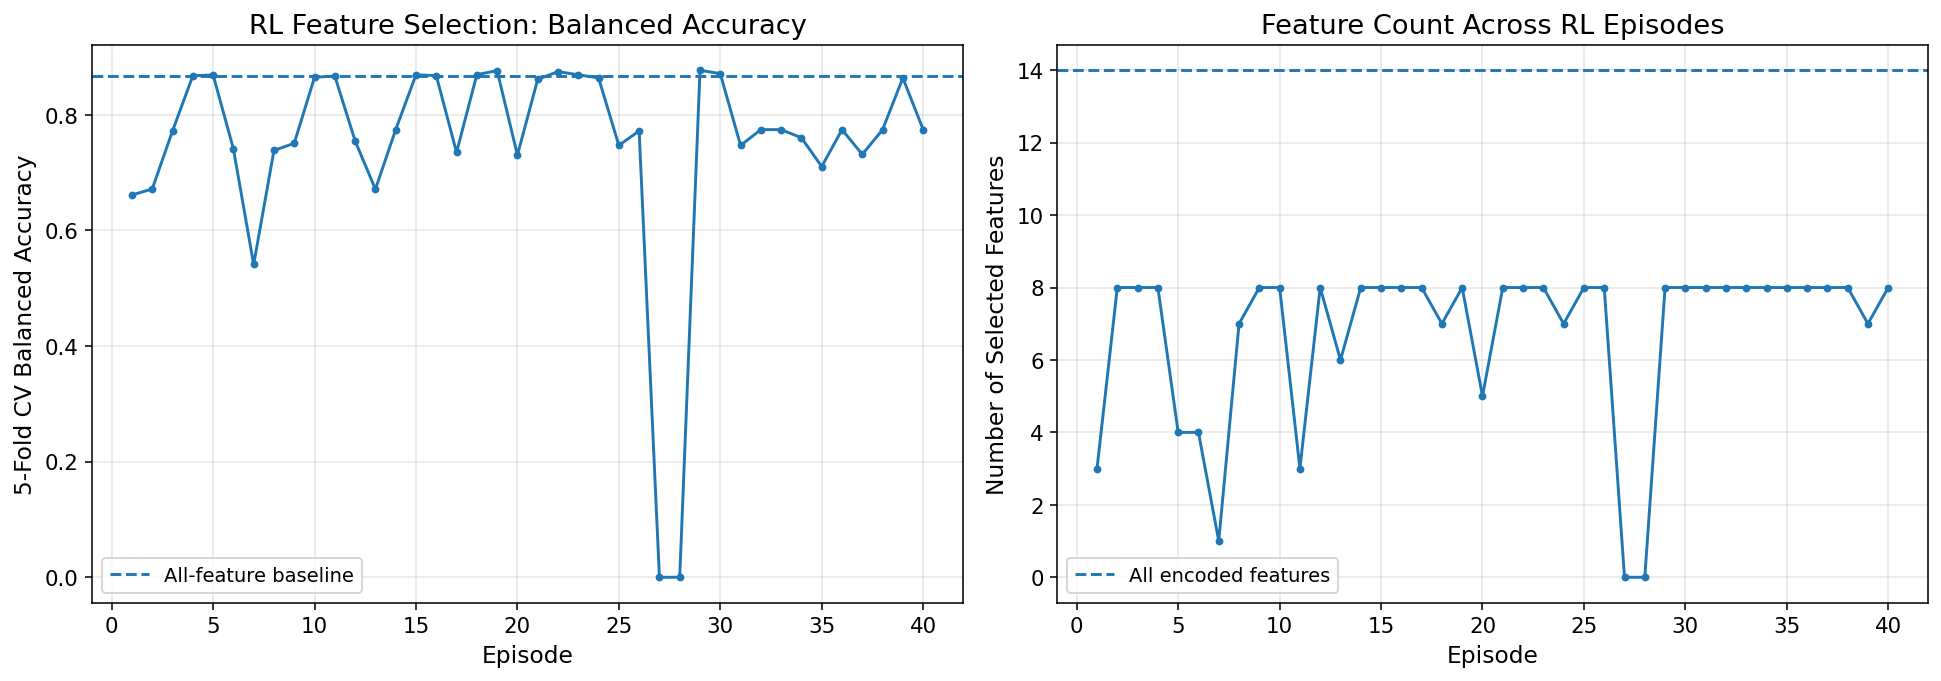

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graph 1: CV balanced accuracy across episodes
axes[0].plot(
    episode_df["episode"],
    episode_df["balanced_accuracy"],
    marker="o",
    markersize=3
)
axes[0].axhline(
    baseline_balanced_accuracy.mean(),
    linestyle="--",
    label="All-feature baseline"
)
axes[0].set_title("RL Feature Selection: Balanced Accuracy")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("5-Fold CV Balanced Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Graph 2: Number of selected features per episode
axes[1].plot(
    episode_df["episode"],
    episode_df["selected_count"],
    marker="o",
    markersize=3
)
axes[1].axhline(
    n_features,
    linestyle="--",
    label="All encoded features"
)
axes[1].set_title("Feature Count Across RL Episodes")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Number of Selected Features")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

from sklearn.base import clone
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np

# Fit the all-feature baseline on the training split
baseline_test_model = clone(baseline_model)
baseline_test_model.fit(X_train_raw, y_train)

baseline_test_predictions = baseline_test_model.predict(X_test_raw)

baseline_test_accuracy = accuracy_score(
    y_test, baseline_test_predictions
)
baseline_test_balanced_accuracy = balanced_accuracy_score(
    y_test, baseline_test_predictions
)

# Transform test data using the preprocessor fitted on training data only
X_test_encoded = preprocessor_rl.transform(X_test_raw)

# Fit an SVM using the best RL-selected subset
rl_test_model = SVC(kernel="rbf", random_state=42)
rl_test_model.fit(
    X_train_encoded[:, list(best_subset)],
    y_train
)

rl_test_predictions = rl_test_model.predict(
    X_test_encoded[:, list(best_subset)]
)

rl_test_accuracy = accuracy_score(y_test, rl_test_predictions)
rl_test_balanced_accuracy = balanced_accuracy_score(
    y_test, rl_test_predictions
)

# Summarize the held-out test results
test_comparison = pd.DataFrame([
    {
        "Method": "Baseline SVM (all features)",
        "Features": n_features,
        "Test Accuracy": baseline_test_accuracy,
        "Test Balanced Accuracy": baseline_test_balanced_accuracy
    },
    {
        "Method": "RL-selected subset",
        "Features": len(best_subset),
        "Test Accuracy": rl_test_accuracy,
        "Test Balanced Accuracy": rl_test_balanced_accuracy
    }
])

display(test_comparison.round(4))

print(
    "Test balanced-accuracy difference (RL - baseline):",
    f"{rl_test_balanced_accuracy - baseline_test_balanced_accuracy:+.4f}"
)
print(
    "Feature-count reduction:",
    f"{(1 - len(best_subset) / n_features) * 100:.1f}%"
)


,Method,Features,Test Accuracy,Test Balanced Accuracy
0,Baseline SVM (all features),14,0.8116,0.8244
1,RL-selected subset,2,0.7971,0.8097


Test balanced-accuracy difference (RL - baseline): -0.0147
Feature-count reduction: 85.7%


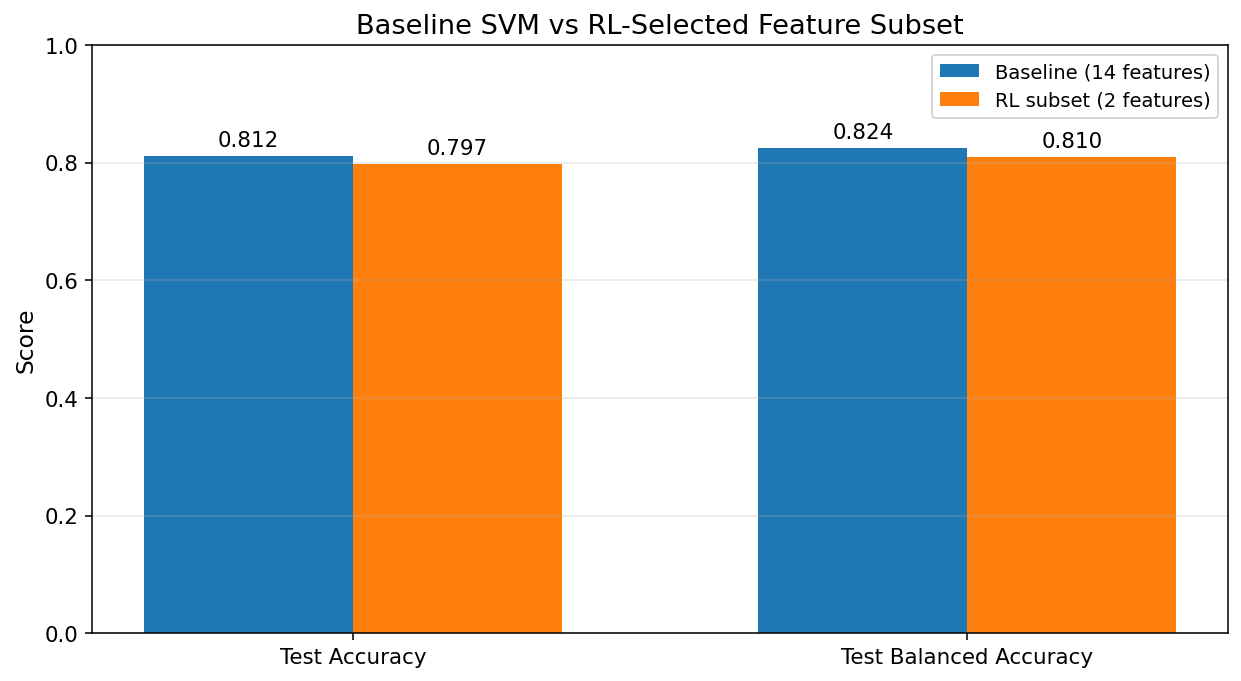

In [ ]:

# Compare test accuracy and balanced accuracy
metrics = ["Test Accuracy", "Test Balanced Accuracy"]

x = np.arange(len(metrics))
width = 0.34

fig, ax = plt.subplots(figsize=(9, 5))

baseline_values = [
    baseline_test_accuracy,
    baseline_test_balanced_accuracy
]
rl_values = [
    rl_test_accuracy,
    rl_test_balanced_accuracy
]

bars1 = ax.bar(
    x - width / 2,
    baseline_values,
    width,
    label=f"Baseline ({n_features} features)"
)
bars2 = ax.bar(
    x + width / 2,
    rl_values,
    width,
    label=f"RL subset ({len(best_subset)} features)"
)

ax.set_title("Baseline SVM vs RL-Selected Feature Subset")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.3)

ax.bar_label(bars1, fmt="%.3f", padding=3)
ax.bar_label(bars2, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()


In [ ]:

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.svm import SVC
import pandas as pd
import numpy as np
import time

stability_results = []

for seed in [11, 22, 33, 44, 55]:
    seed_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    # Evaluate the selected subset
    selected_scores = cross_val_score(
        SVC(kernel="rbf", random_state=42),
        X_train_encoded[:, list(best_subset)],
        y_train,
        cv=seed_cv,
        scoring="balanced_accuracy",
        n_jobs=-1
    )

    # Evaluate all features using the same CV splits
    all_feature_scores = cross_val_score(
        clone(baseline_model),
        X_train_raw,
        y_train,
        cv=seed_cv,
        scoring="balanced_accuracy",
        n_jobs=-1
    )

    stability_results.append({
        "Seed": seed,
        "Baseline BA": all_feature_scores.mean(),
        "RL Subset BA": selected_scores.mean(),
        "Difference (RL - Baseline)": (
            selected_scores.mean() - all_feature_scores.mean()
        )
    })

stability_df = pd.DataFrame(stability_results)

display(stability_df.round(4))

print("\nMean balanced accuracy across seeds:")
print("Baseline:", round(stability_df["Baseline BA"].mean(), 4))
print("RL subset:", round(stability_df["RL Subset BA"].mean(), 4))
print(
    "Mean difference:",
    round(stability_df["Difference (RL - Baseline)"].mean(), 4)
)


,Seed,Baseline BA,RL Subset BA,Difference (RL - Baseline)
0,11,0.8734,0.8728,-0.0006
1,22,0.8725,0.8733,0.0007
2,33,0.8684,0.8731,0.0047
3,44,0.8678,0.8710,0.0033
4,55,0.8677,0.8732,0.0055



Mean balanced accuracy across seeds:
Baseline: 0.87
RL subset: 0.8727
Mean difference: 0.0027


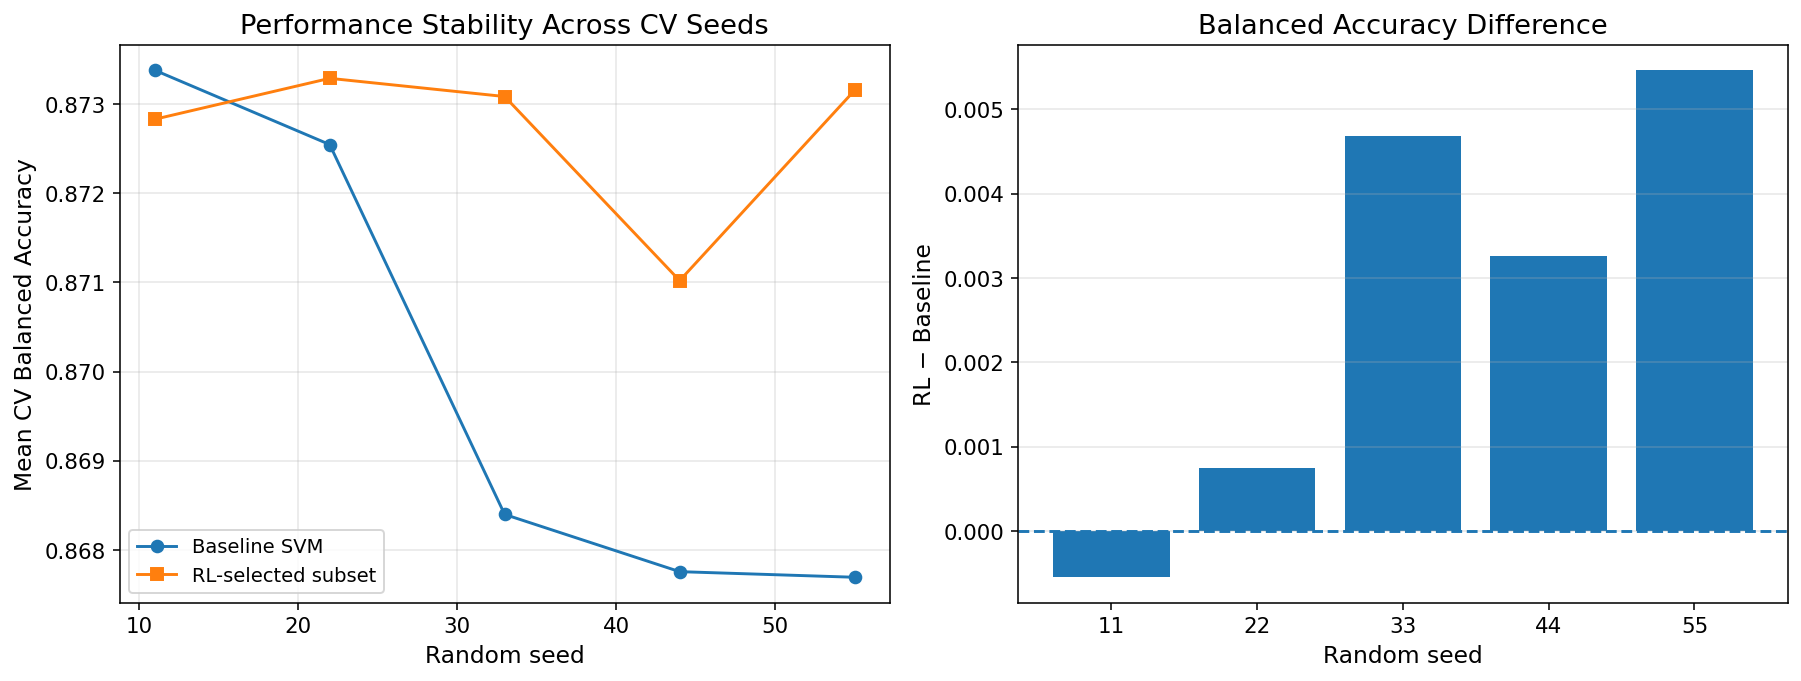

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Graph 1: Balanced accuracy across seeds
axes[0].plot(
    stability_df["Seed"],
    stability_df["Baseline BA"],
    marker="o",
    label="Baseline SVM"
)
axes[0].plot(
    stability_df["Seed"],
    stability_df["RL Subset BA"],
    marker="s",
    label="RL-selected subset"
)
axes[0].set_title("Performance Stability Across CV Seeds")
axes[0].set_xlabel("Random seed")
axes[0].set_ylabel("Mean CV Balanced Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Graph 2: Difference between methods
axes[1].bar(
    stability_df["Seed"].astype(str),
    stability_df["Difference (RL - Baseline)"]
)
axes[1].axhline(0, linestyle="--")
axes[1].set_title("Balanced Accuracy Difference")
axes[1].set_xlabel("Random seed")
axes[1].set_ylabel("RL − Baseline")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

# Re-run the agent while recording maximum Q-values per episode
random.seed(42)
np.random.seed(42)

q_table = {}
tracked_history = []

tracking_start = time.time()

for episode in range(N_EPISODES):
    state = tuple()

    epsilon = EPSILON_END + (
        EPSILON_START - EPSILON_END
    ) * (1 - episode / max(1, N_EPISODES - 1))

    for step in range(MAX_STEPS):
        action = choose_action(state, epsilon)

        if action == n_features:
            reward = calculate_reward(state)
            old_q = get_q_values(state)[action]
            get_q_values(state)[action] = old_q + ALPHA * (
                reward - old_q
            )
            break

        next_state = tuple(sorted(state + (action,)))
        reward = calculate_reward(next_state)

        next_q_values = get_q_values(next_state)
        available_next = [
            i for i in range(n_features) if i not in next_state
        ]
        available_next.append(n_features)

        best_next_q = max(
            next_q_values[i] for i in available_next
        )

        old_q = get_q_values(state)[action]
        get_q_values(state)[action] = old_q + ALPHA * (
            reward + GAMMA * best_next_q - old_q
        )

        state = next_state

    # Record the maximum Q-value currently learned
    max_q_value = max(
        float(np.max(values)) for values in q_table.values()
    )

    tracked_history.append({
        "episode": episode + 1,
        "epsilon": epsilon,
        "max_q_value": max_q_value,
        "selected_count": len(state),
        "balanced_accuracy": (
            evaluate_feature_subset(state) if state else 0.0
        )
    })

tracked_df = pd.DataFrame(tracked_history)

print(f"Tracked training completed in {time.time() - tracking_start:.2f} seconds.")
display(tracked_df.head())
print("Episodes recorded:", len(tracked_df))


Tracked training completed in 0.03 seconds.


,episode,epsilon,max_q_value,selected_count,balanced_accuracy
0,1,1.000000,0.131407,3,0.661319
1,2,0.976923,0.132049,8,0.671673
2,3,0.953846,0.152275,8,0.772151
3,4,0.930769,0.244897,8,0.867488
4,5,0.907692,0.244897,4,0.869032


Episodes recorded: 40


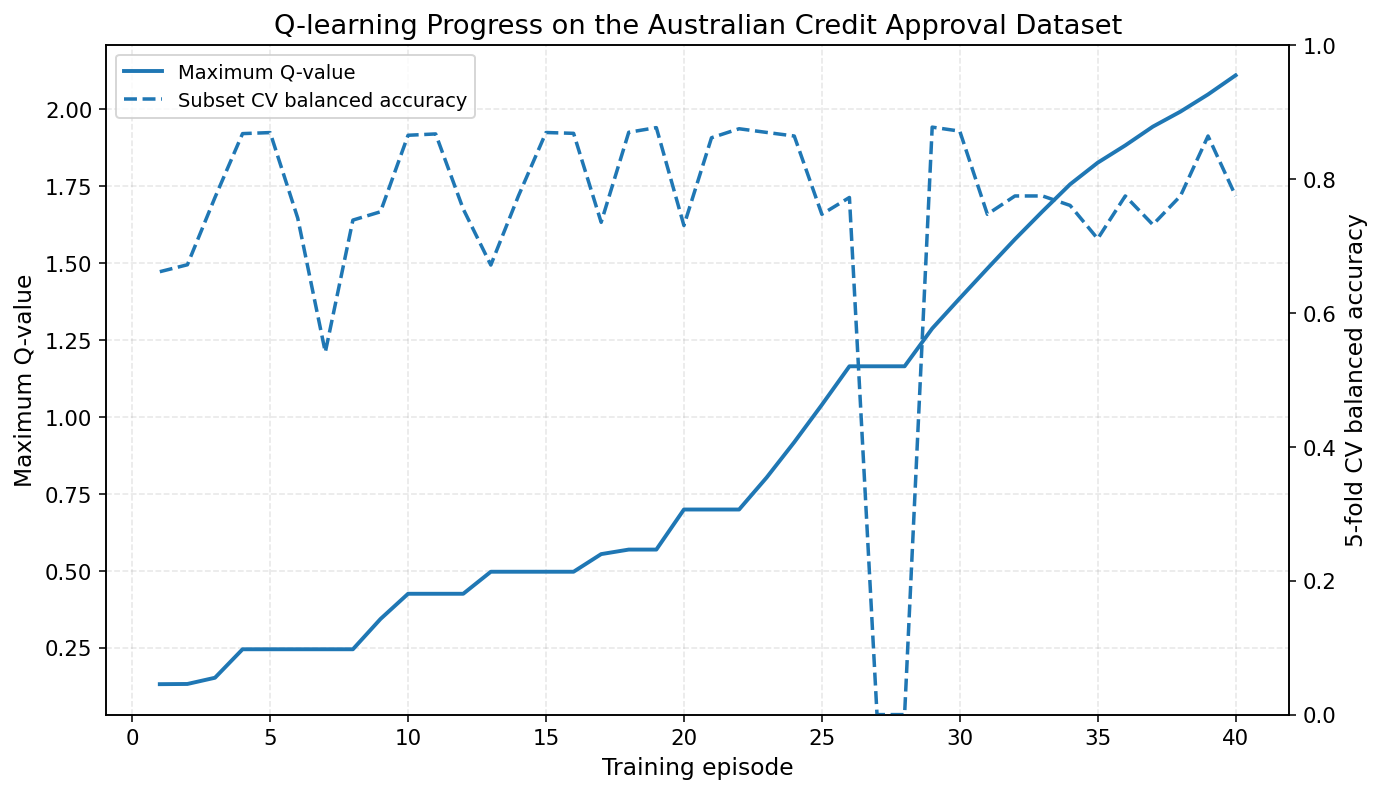

Saved: improved_graph1_learning_progress.png


In [ ]:

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "figure.dpi": 140,
    "savefig.dpi": 300
})

fig, ax1 = plt.subplots(figsize=(10, 5.8))

# Left axis: maximum Q-value
line1 = ax1.plot(
    tracked_df["episode"],
    tracked_df["max_q_value"],
    linewidth=2,
    label="Maximum Q-value"
)

ax1.set_xlabel("Training episode")
ax1.set_ylabel("Maximum Q-value")
ax1.grid(True, linestyle="--", alpha=0.3)

# Right axis: balanced accuracy
ax2 = ax1.twinx()

line2 = ax2.plot(
    tracked_df["episode"],
    tracked_df["balanced_accuracy"],
    linewidth=1.8,
    linestyle="--",
    label="Subset CV balanced accuracy"
)

ax2.set_ylabel("5-fold CV balanced accuracy")
ax2.set_ylim(0, 1)

lines = line1 + line2
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc="best", frameon=True)

ax1.set_title(
    "Q-learning Progress on the Australian Credit Approval Dataset"
)

fig.tight_layout()
fig.savefig(
    "improved_graph1_learning_progress.png",
    bbox_inches="tight"
)
plt.show()

print("Saved: improved_graph1_learning_progress.png")


In [ ]:

def run_epsilon_experiment(epsilon, episodes=40, max_steps=8):
    local_q = {}
    visited_states = {tuple()}
    rows = []

    def local_q_values(state):
        if state not in local_q:
            local_q[state] = np.zeros(n_features + 1)
        return local_q[state]

    def local_choose_action(state):
        available = [
            i for i in range(n_features) if i not in state
        ]
        available.append(n_features)  # STOP

        if random.random() < epsilon:
            return random.choice(available)

        q_values = local_q_values(state)
        best = max(q_values[a] for a in available)
        choices = [a for a in available if q_values[a] == best]
        return random.choice(choices)

    for episode in range(episodes):
        state = tuple()

        for _ in range(max_steps):
            action = local_choose_action(state)

            if action == n_features:
                reward = calculate_reward(state)
                q_values = local_q_values(state)
                q_values[action] += ALPHA * (
                    reward - q_values[action]
                )
                break

            next_state = tuple(sorted(state + (action,)))
            visited_states.add(next_state)
            reward = calculate_reward(next_state)

            next_q = local_q_values(next_state)
            available_next = [
                i for i in range(n_features) if i not in next_state
            ]
            available_next.append(n_features)

            target = reward + GAMMA * max(
                next_q[a] for a in available_next
            )

            q_values = local_q_values(state)
            q_values[action] += ALPHA * (
                target - q_values[action]
            )

            state = next_state

        rows.append({
            "episode": episode + 1,
            "epsilon": epsilon,
            "unique_states_visited": len(visited_states)
        })

    return pd.DataFrame(rows)


epsilon_values = [0.1, 0.3, 0.5, 0.7]
epsilon_runs = []

epsilon_start_time = time.time()

for eps in epsilon_values:
    run_df = run_epsilon_experiment(eps)
    epsilon_runs.append(run_df)

epsilon_results = pd.concat(epsilon_runs, ignore_index=True)

print(
    "Epsilon experiment completed in",
    f"{time.time() - epsilon_start_time:.2f} seconds"
)

display(
    epsilon_results.groupby("epsilon")[
        "unique_states_visited"
    ].agg(["min", "max", "last"]).reset_index()
)


Epsilon experiment completed in 0.02 seconds


,epsilon,min,max,last
0,0.1,9,65,65
1,0.3,5,139,139
2,0.5,5,137,137
3,0.7,9,191,191


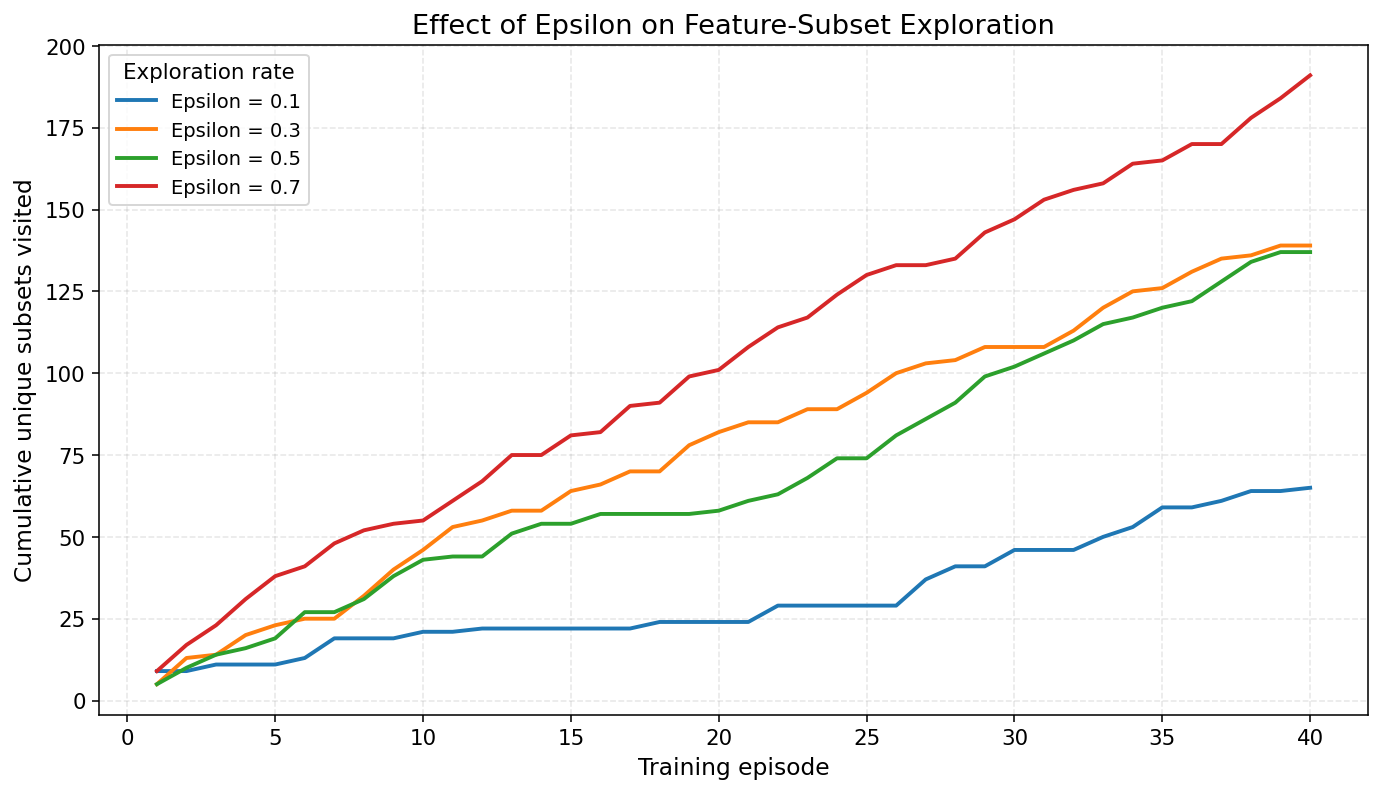

Saved: improved_graph2_epsilon_comparison.png


In [ ]:

fig, ax = plt.subplots(figsize=(10, 5.8))

for eps in epsilon_values:
    run_data = epsilon_results[
        epsilon_results["epsilon"] == eps
    ]

    ax.plot(
        run_data["episode"],
        run_data["unique_states_visited"],
        linewidth=2,
        label=f"Epsilon = {eps}"
    )

ax.set_title(
    "Effect of Epsilon on Feature-Subset Exploration"
)
ax.set_xlabel("Training episode")
ax.set_ylabel("Cumulative unique subsets visited")
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(title="Exploration rate", frameon=True)

fig.tight_layout()
fig.savefig(
    "improved_graph2_epsilon_comparison.png",
    bbox_inches="tight"
)
plt.show()

print("Saved: improved_graph2_epsilon_comparison.png")


In [ ]:

# Summarize observed performance by number of selected features
feature_count_results = (
    subset_results_df[
        subset_results_df["feature_count"] > 0
    ]
    .groupby("feature_count")
    .agg(
        best_balanced_accuracy=("balanced_accuracy", "max"),
        mean_balanced_accuracy=("balanced_accuracy", "mean"),
        subsets_evaluated=("balanced_accuracy", "count")
    )
    .reset_index()
    .sort_values("feature_count")
)

display(feature_count_results.round(4))

print(
    "Subset sizes observed:",
    feature_count_results["feature_count"].tolist()
)
print(
    "Total unique non-empty subsets:",
    int(feature_count_results["subsets_evaluated"].sum())
)


,feature_count,best_balanced_accuracy,mean_balanced_accuracy,subsets_evaluated
0,1,0.8731,0.6248,9
1,2,0.8748,0.6948,16
2,3,0.8731,0.7207,22
3,4,0.8769,0.7483,22
4,5,0.8708,0.7577,22
5,6,0.8724,0.7747,21
6,7,0.8758,0.7914,23
7,8,0.8772,0.8054,20


Subset sizes observed: [1, 2, 3, 4, 5, 6, 7, 8]
Total unique non-empty subsets: 155


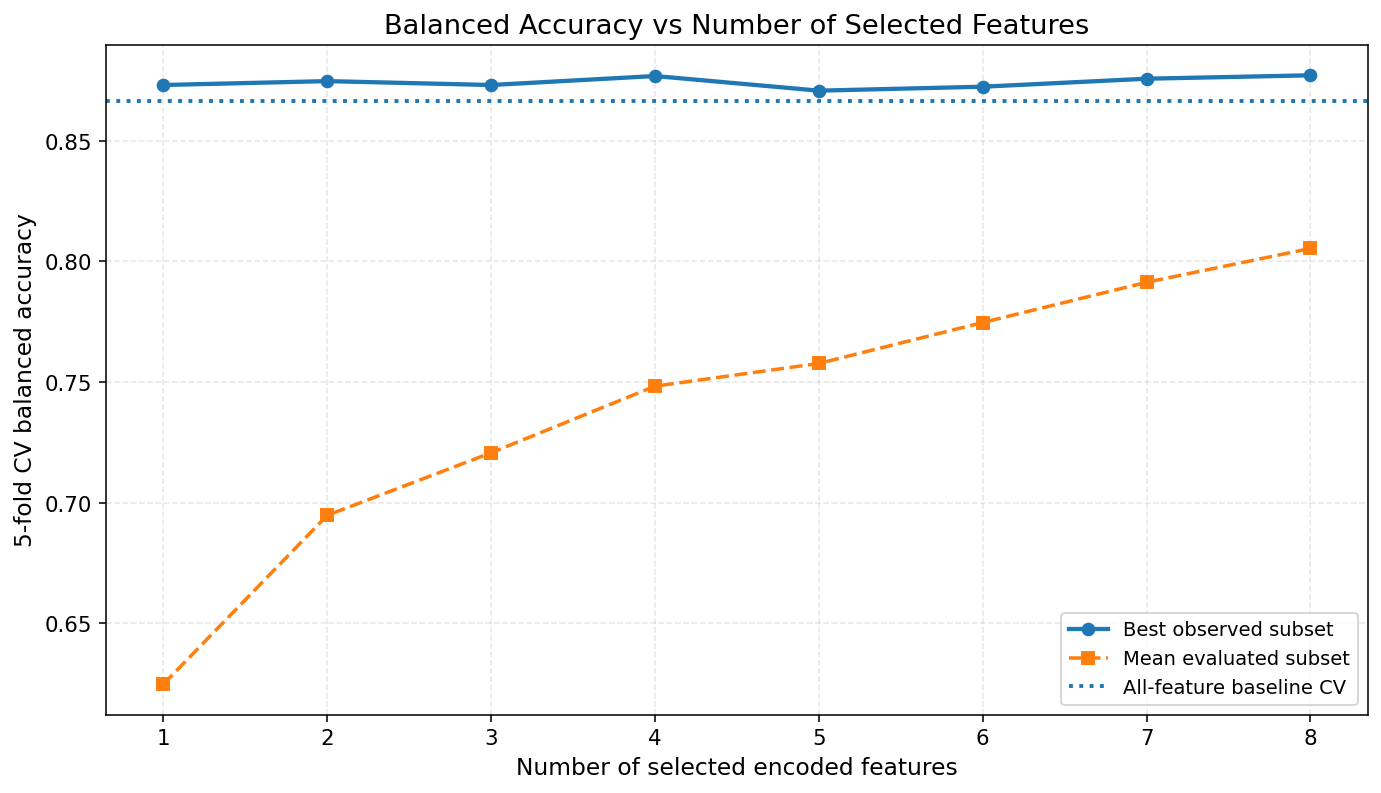

Saved: improved_graph3_accuracy_vs_feature_count.png


In [ ]:

fig, ax = plt.subplots(figsize=(10, 5.8))

ax.plot(
    feature_count_results["feature_count"],
    feature_count_results["best_balanced_accuracy"],
    marker="o",
    linewidth=2.2,
    label="Best observed subset"
)

ax.plot(
    feature_count_results["feature_count"],
    feature_count_results["mean_balanced_accuracy"],
    marker="s",
    linestyle="--",
    linewidth=1.8,
    label="Mean evaluated subset"
)

ax.axhline(
    baseline_balanced_accuracy.mean(),
    linestyle=":",
    linewidth=2,
    label="All-feature baseline CV"
)

ax.set_title(
    "Balanced Accuracy vs Number of Selected Features"
)
ax.set_xlabel("Number of selected encoded features")
ax.set_ylabel("5-fold CV balanced accuracy")
ax.set_xticks(feature_count_results["feature_count"])
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(frameon=True)

fig.tight_layout()
fig.savefig(
    "improved_graph3_accuracy_vs_feature_count.png",
    bbox_inches="tight"
)
plt.show()

print("Saved: improved_graph3_accuracy_vs_feature_count.png")


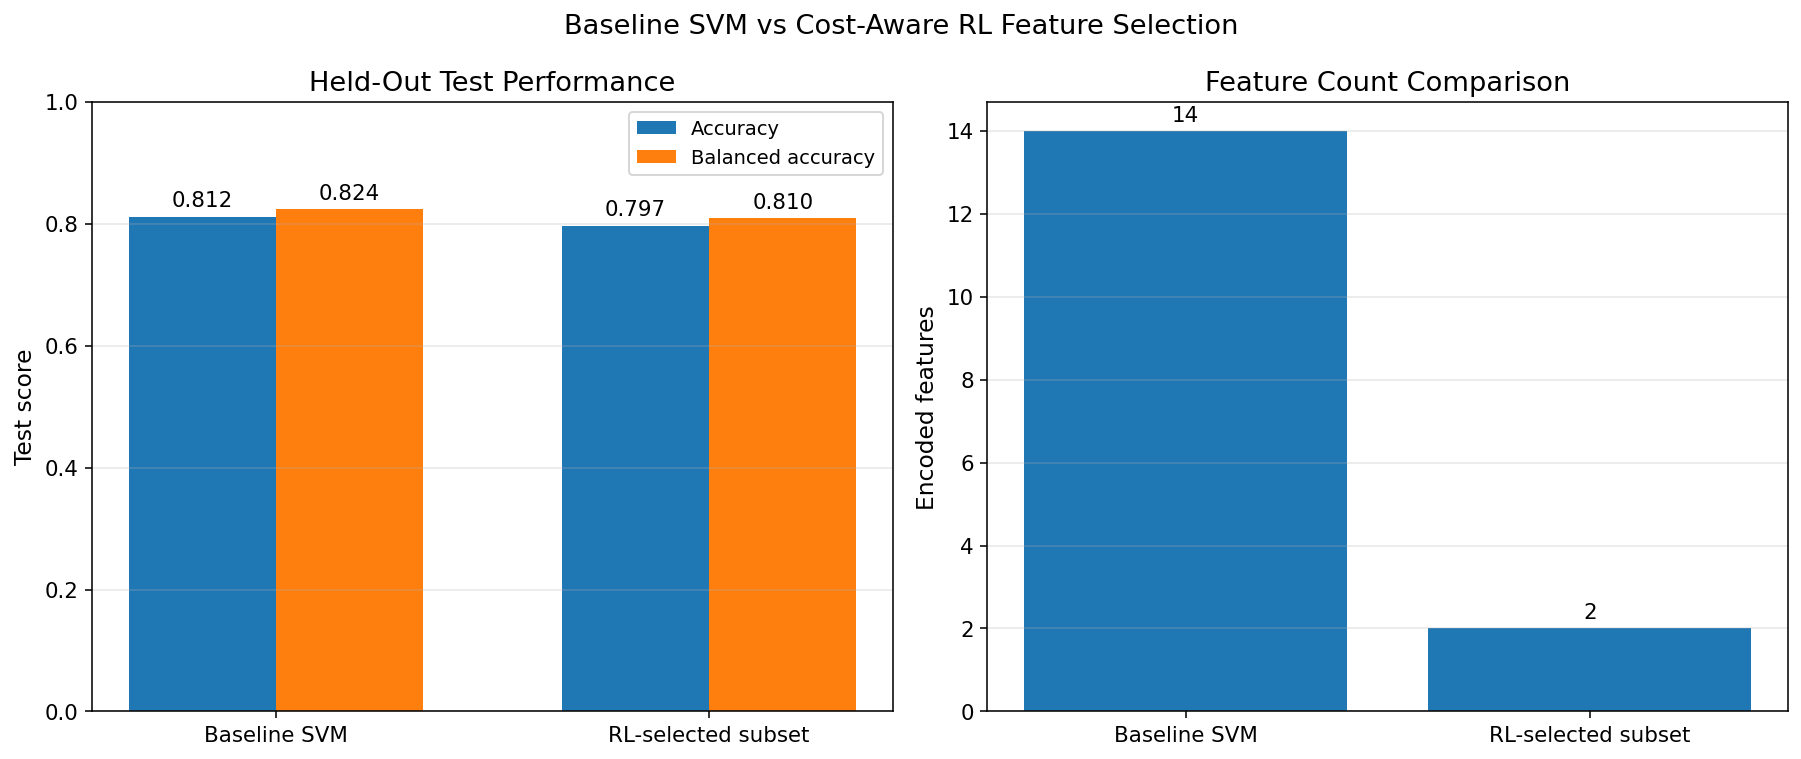

Saved: improved_graph4_baseline_vs_rl.png
Test balanced-accuracy difference: -0.0147
Feature reduction: 85.7%


In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# Panel 1: Held-out test performance
methods = ["Baseline SVM", "RL-selected subset"]
test_acc = [baseline_test_accuracy, rl_test_accuracy]
test_bal_acc = [
    baseline_test_balanced_accuracy,
    rl_test_balanced_accuracy
]

x = np.arange(len(methods))
width = 0.34

bars1 = axes[0].bar(
    x - width / 2, test_acc, width, label="Accuracy"
)
bars2 = axes[0].bar(
    x + width / 2, test_bal_acc, width,
    label="Balanced accuracy"
)

axes[0].set_xticks(x)
axes[0].set_xticklabels(methods)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Test score")
axes[0].set_title("Held-Out Test Performance")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

axes[0].bar_label(bars1, fmt="%.3f", padding=3)
axes[0].bar_label(bars2, fmt="%.3f", padding=3)

# Panel 2: Number of selected features
feature_counts = [n_features, len(best_subset)]

bars = axes[1].bar(methods, feature_counts)
axes[1].set_ylabel("Encoded features")
axes[1].set_title("Feature Count Comparison")
axes[1].grid(axis="y", alpha=0.3)
axes[1].bar_label(bars, fmt="%d", padding=3)

plt.suptitle(
    "Baseline SVM vs Cost-Aware RL Feature Selection",
    fontsize=14
)
plt.tight_layout()
plt.savefig(
    "improved_graph4_baseline_vs_rl.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved: improved_graph4_baseline_vs_rl.png")
print(
    "Test balanced-accuracy difference:",
    f"{rl_test_balanced_accuracy - baseline_test_balanced_accuracy:+.4f}"
)
print(
    "Feature reduction:",
    f"{(1 - len(best_subset) / n_features) * 100:.1f}%"
)


In [ ]:

import os
import zipfile
import pandas as pd

output_dir = "RL_Improvement_Results"
os.makedirs(output_dir, exist_ok=True)

# Save experimental tables
episode_df.to_csv(
    f"{output_dir}/original_training_history.csv", index=False
)
tracked_df.to_csv(
    f"{output_dir}/tracked_learning_history.csv", index=False
)
epsilon_results.to_csv(
    f"{output_dir}/epsilon_experiment.csv", index=False
)
feature_count_results.to_csv(
    f"{output_dir}/feature_count_comparison.csv", index=False
)
subset_results_df.to_csv(
    f"{output_dir}/evaluated_feature_subsets.csv", index=False
)
stability_df.to_csv(
    f"{output_dir}/stability_across_seeds.csv", index=False
)
test_comparison.to_csv(
    f"{output_dir}/held_out_test_comparison.csv", index=False
)

# Save the four generated graphs if they exist
graph_files = [
    "improved_graph1_learning_progress.png",
    "improved_graph2_epsilon_comparison.png",
    "improved_graph3_accuracy_vs_feature_count.png",
    "improved_graph4_baseline_vs_rl.png"
]

for graph in graph_files:
    if os.path.exists(graph):
        os.replace(graph, f"{output_dir}/{graph}")

# Bundle everything
zip_name = "RL_Improvement_Results.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zf:
    for root, _, files in os.walk(output_dir):
        for filename in files:
            full_path = os.path.join(root, filename)
            zf.write(
                full_path,
                arcname=os.path.relpath(full_path, output_dir)
            )

print("Export completed:", zip_name)
print("Files included:")
for filename in sorted(os.listdir(output_dir)):
    print("-", filename)

print("\nDownload the ZIP from the Colab Files panel.")


Export completed: RL_Improvement_Results.zip
Files included:
- epsilon_experiment.csv
- evaluated_feature_subsets.csv
- feature_count_comparison.csv
- held_out_penalty_ablation.csv
- held_out_test_comparison.csv
- improved_graph1_learning_progress.png
- improved_graph2_epsilon_comparison.png
- improved_graph3_accuracy_vs_feature_count.png
- improved_graph4_baseline_vs_rl.png
- improved_graph5_reward_penalty_ablation.png
- improved_graph6_test_penalty_comparison.png
- original_training_history.csv
- reward_penalty_ablation.csv
- reward_penalty_ablation_summary.csv
- stability_across_seeds.csv
- tracked_learning_history.csv

Download the ZIP from the Colab Files panel.


In [ ]:

# Step 22: Reward penalty ablation study

from sklearn.model_selection import cross_val_score
from sklearn.svm import SVC
import pandas as pd
import numpy as np

penalty_values = [0.00, 0.02, 0.05]
ablation_rows = []

# Use the same previously evaluated candidate subsets for every penalty.
candidate_subsets = list(subset_score_cache.keys())

for penalty in penalty_values:
    for subset in candidate_subsets:
        if not subset:
            continue

        cv_score = evaluate_feature_subset(subset)
        feature_count = len(subset)
        reward = cv_score - penalty * (feature_count / n_features)

        ablation_rows.append({
            "penalty": penalty,
            "feature_count": feature_count,
            "cv_balanced_accuracy": cv_score,
            "reward": reward,
            "selected_features": str(subset)
        })

ablation_df = pd.DataFrame(ablation_rows)

ablation_summary = (
    ablation_df.sort_values(
        ["penalty", "reward"],
        ascending=[True, False]
    )
    .groupby("penalty", as_index=False)
    .first()
)

print("Best candidate under each penalty:")
display(ablation_summary)

ablation_df.to_csv(
    "reward_penalty_ablation.csv", index=False
)
ablation_summary.to_csv(
    "reward_penalty_ablation_summary.csv", index=False
)
print("Saved both ablation tables.")


Best candidate under each penalty:


,penalty,feature_count,cv_balanced_accuracy,reward,selected_features
0,0.00,6,0.883310,0.883310,"(1, 3, 5, 6, 7, 9)"
1,0.02,3,0.882562,0.878276,"(2, 7, 11)"
2,0.05,3,0.882562,0.871848,"(2, 7, 11)"


Saved both ablation tables.


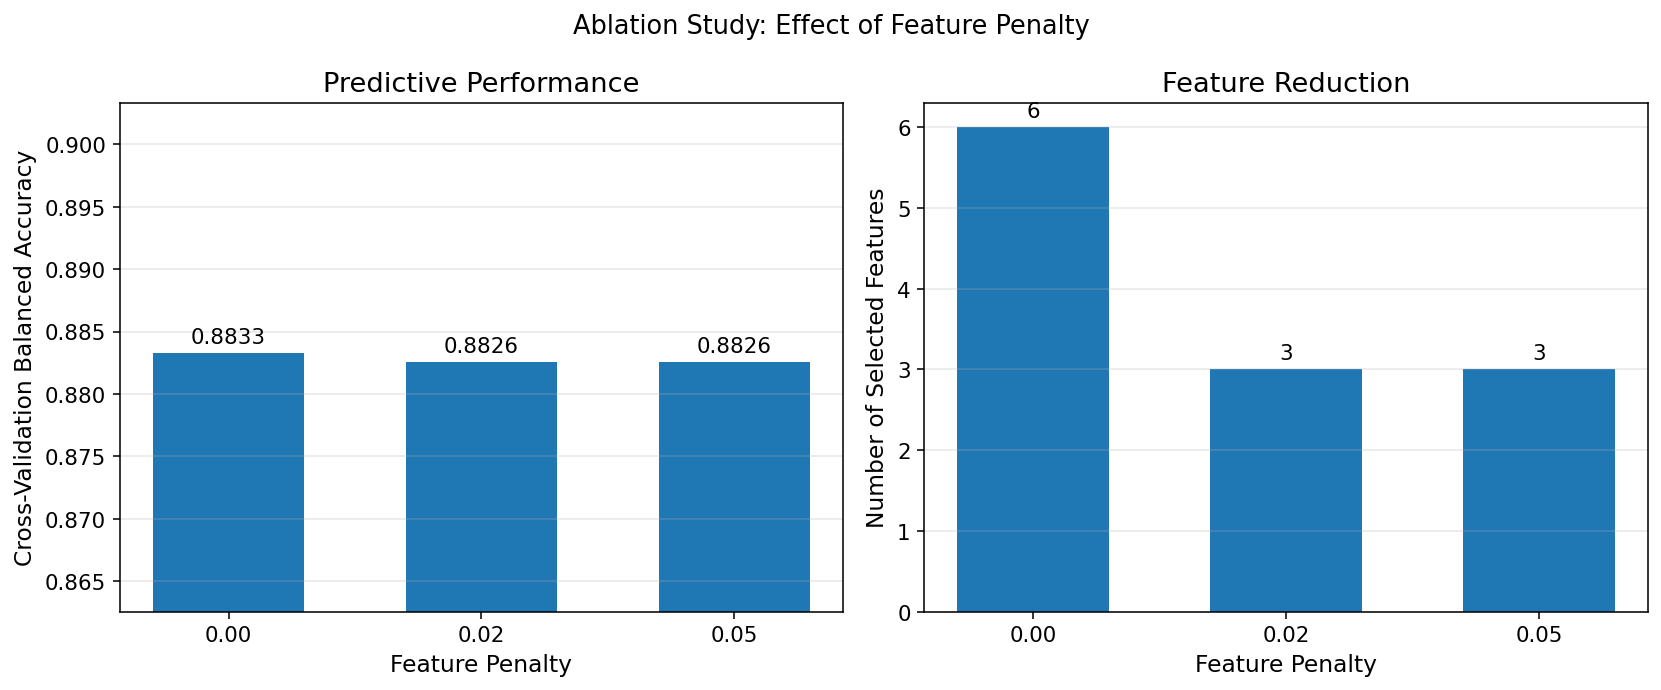

Saved: improved_graph5_reward_penalty_ablation.png


In [ ]:

# Step 23: Plot reward-penalty ablation results

import matplotlib.pyplot as plt
import numpy as np

summary = ablation_summary.sort_values("penalty")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

labels = [f"{p:.2f}" for p in summary["penalty"]]
x = np.arange(len(labels))

bars1 = axes[0].bar(
    x, summary["cv_balanced_accuracy"], width=0.6
)
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_xlabel("Feature Penalty")
axes[0].set_ylabel("Cross-Validation Balanced Accuracy")
axes[0].set_title("Predictive Performance")
axes[0].set_ylim(
    max(0, summary["cv_balanced_accuracy"].min() - 0.02),
    min(1, summary["cv_balanced_accuracy"].max() + 0.02)
)
axes[0].bar_label(bars1, fmt="%.4f", padding=3)
axes[0].grid(axis="y", alpha=0.3)

bars2 = axes[1].bar(
    x, summary["feature_count"], width=0.6
)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_xlabel("Feature Penalty")
axes[1].set_ylabel("Number of Selected Features")
axes[1].set_title("Feature Reduction")
axes[1].bar_label(bars2, fmt="%d", padding=3)
axes[1].grid(axis="y", alpha=0.3)

plt.suptitle("Ablation Study: Effect of Feature Penalty")
plt.tight_layout()
plt.savefig(
    "improved_graph5_reward_penalty_ablation.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

print("Saved: improved_graph5_reward_penalty_ablation.png")


In [ ]:

# Step 24: Held-out test evaluation for each penalty

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score
import pandas as pd

test_ablation_rows = []

for _, row in ablation_summary.iterrows():
    penalty = float(row["penalty"])

    # Recover the candidate feature subset
    subset = tuple(
        int(x.strip())
        for x in row["selected_features"].strip("()").split(",")
        if x.strip()
    )

    model = SVC(kernel="rbf", random_state=42)
    model.fit(
        X_train_encoded[:, list(subset)],
        y_train
    )

    predictions = model.predict(
        X_test_encoded[:, list(subset)]
    )

    test_ablation_rows.append({
        "penalty": penalty,
        "feature_count": len(subset),
        "selected_features": str(subset),
        "test_accuracy": accuracy_score(y_test, predictions),
        "test_balanced_accuracy": balanced_accuracy_score(
            y_test, predictions
        )
    })

test_ablation_df = pd.DataFrame(test_ablation_rows)

print("Held-out test results:")
display(test_ablation_df.round(4))

test_ablation_df.to_csv(
    "held_out_penalty_ablation.csv",
    index=False
)
print("Saved: held_out_penalty_ablation.csv")


Held-out test results:


,penalty,feature_count,selected_features,test_accuracy,test_balanced_accuracy
0,0.00,6,"(1, 3, 5, 6, 7, 9)",0.8043,0.8162
1,0.02,3,"(2, 7, 11)",0.7826,0.7950
2,0.05,3,"(2, 7, 11)",0.7826,0.7950


Saved: held_out_penalty_ablation.csv


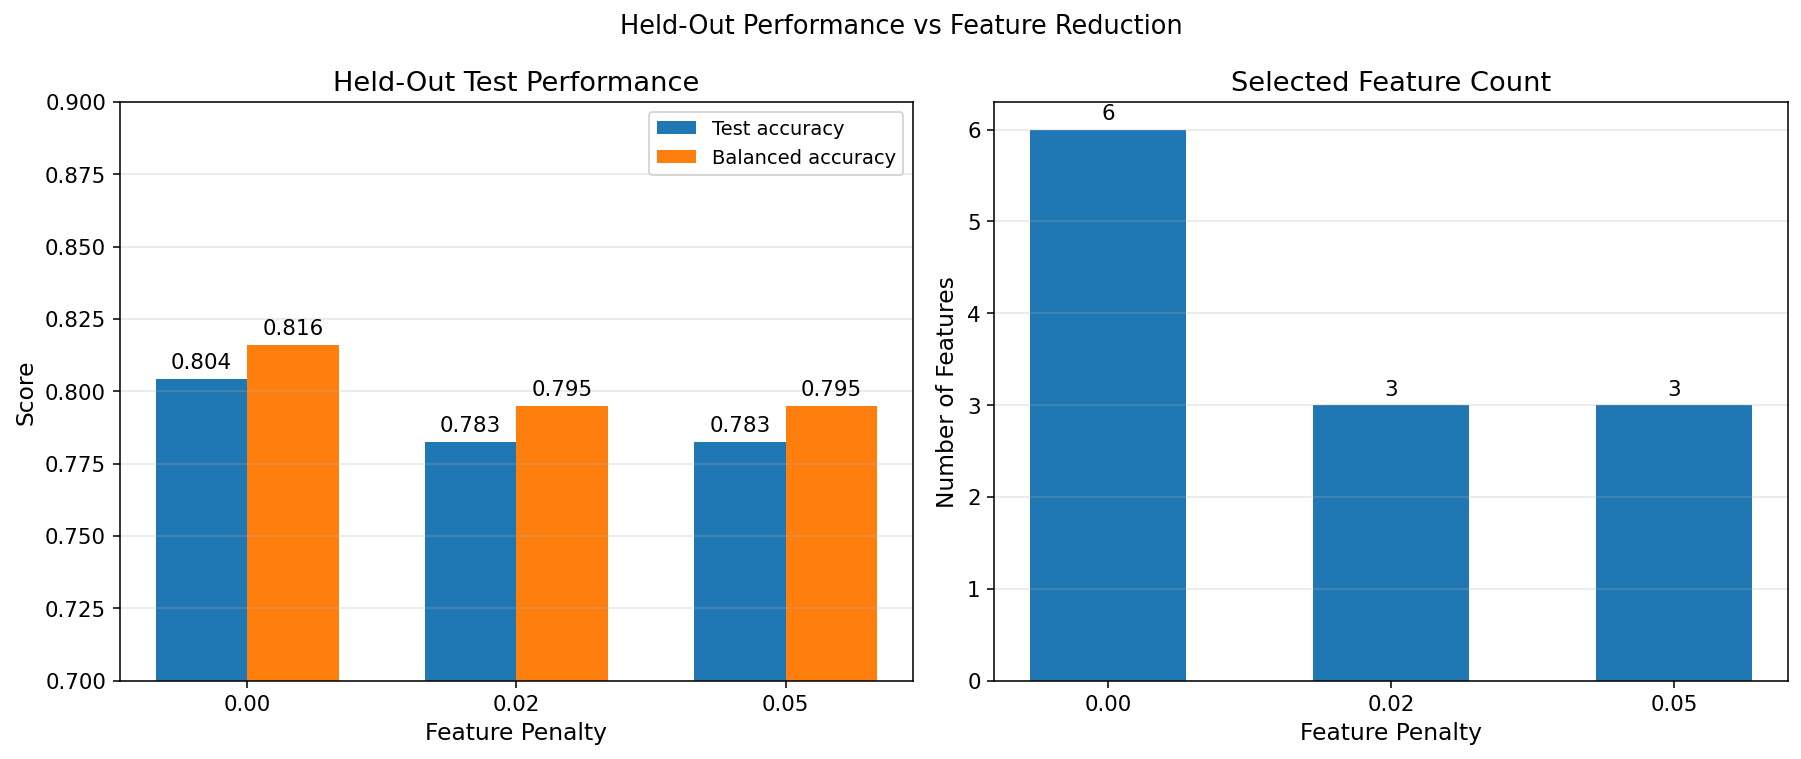

Saved: improved_graph6_test_penalty_comparison.png


In [ ]:

# Step 25: Visualize held-out test ablation results

import matplotlib.pyplot as plt
import numpy as np

results = test_ablation_df.sort_values("penalty").reset_index(drop=True)

labels = [f"{p:.2f}" for p in results["penalty"]]
x = np.arange(len(labels))
width = 0.34

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# Test performance comparison
bars1 = axes[0].bar(
    x - width / 2,
    results["test_accuracy"],
    width,
    label="Test accuracy"
)
bars2 = axes[0].bar(
    x + width / 2,
    results["test_balanced_accuracy"],
    width,
    label="Balanced accuracy"
)

axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_xlabel("Feature Penalty")
axes[0].set_ylabel("Score")
axes[0].set_title("Held-Out Test Performance")
axes[0].set_ylim(0.70, 0.90)
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)
axes[0].bar_label(bars1, fmt="%.3f", padding=3)
axes[0].bar_label(bars2, fmt="%.3f", padding=3)

# Feature count comparison
bars3 = axes[1].bar(
    x,
    results["feature_count"],
    width=0.55
)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_xlabel("Feature Penalty")
axes[1].set_ylabel("Number of Features")
axes[1].set_title("Selected Feature Count")
axes[1].grid(axis="y", alpha=0.3)
axes[1].bar_label(bars3, fmt="%d", padding=3)

plt.suptitle("Held-Out Performance vs Feature Reduction")
plt.tight_layout()

plt.savefig(
    "improved_graph6_test_penalty_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved: improved_graph6_test_penalty_comparison.png")


In [ ]:

# Step 26: Package all experiment results and graphs

import os
import zipfile
import pandas as pd

output_dir = "RL_Improvement_Results"
os.makedirs(output_dir, exist_ok=True)

# Collect all available result tables
result_files = [
    "original_training_history.csv",
    "tracked_learning_history.csv",
    "epsilon_experiment.csv",
    "feature_count_comparison.csv",
    "evaluated_feature_subsets.csv",
    "stability_across_seeds.csv",
    "held_out_test_comparison.csv",
    "reward_penalty_ablation.csv",
    "reward_penalty_ablation_summary.csv",
    "held_out_penalty_ablation.csv"
]

# Save the latest versions of the new ablation tables
new_tables = {
    "reward_penalty_ablation.csv": ablation_df,
    "reward_penalty_ablation_summary.csv": ablation_summary,
    "held_out_penalty_ablation.csv": test_ablation_df
}

for filename, dataframe in new_tables.items():
    dataframe.to_csv(filename, index=False)

# Include all six generated graphs
graph_files = [
    "improved_graph1_learning_progress.png",
    "improved_graph2_epsilon_comparison.png",
    "improved_graph3_accuracy_vs_feature_count.png",
    "improved_graph4_baseline_vs_rl.png",
    "improved_graph5_reward_penalty_ablation.png",
    "improved_graph6_test_penalty_comparison.png"
]

# Copy available result tables into the output folder
for filename in result_files:
    if os.path.exists(filename):
        with open(filename, "rb") as source:
            with open(os.path.join(output_dir, filename), "wb") as target:
                target.write(source.read())

# Copy available graphs
for filename in graph_files:
    if os.path.exists(filename):
        with open(filename, "rb") as source:
            with open(os.path.join(output_dir, filename), "wb") as target:
                target.write(source.read())

# Create the updated ZIP
zip_name = "RL_Improvement_Results_Final.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zf:
    for root, _, filenames in os.walk(output_dir):
        for filename in filenames:
            path = os.path.join(root, filename)
            zf.write(path, arcname=os.path.relpath(path, output_dir))

print("Updated results package created:", zip_name)
print("\nFiles included:")
for filename in sorted(os.listdir(output_dir)):
    print("-", filename)

print("\nTo download, open the Colab Files panel and download", zip_name)


Updated results package created: RL_Improvement_Results_Final.zip

Files included:
- epsilon_experiment.csv
- evaluated_feature_subsets.csv
- feature_count_comparison.csv
- held_out_penalty_ablation.csv
- held_out_test_comparison.csv
- improved_graph1_learning_progress.png
- improved_graph2_epsilon_comparison.png
- improved_graph3_accuracy_vs_feature_count.png
- improved_graph4_baseline_vs_rl.png
- improved_graph5_reward_penalty_ablation.png
- improved_graph6_test_penalty_comparison.png
- original_training_history.csv
- reward_penalty_ablation.csv
- reward_penalty_ablation_summary.csv
- stability_across_seeds.csv
- tracked_learning_history.csv

To download, open the Colab Files panel and download RL_Improvement_Results_Final.zip
